☕ Café, Sono e Saúde — Checkpoint Cientista de Dados (Nível 1)
Empresa: Health & Life Analytics Objetivo: entender como o consumo de café se relaciona com hábitos de sono e condições de saúde e, no final, prever a qualidade do sono (Sleep_Quality).

Estrutura do notebook

Parte	O que fazemos
0	Preparar o ambiente e carregar os dados
1	Análise Exploratória de Dados (EDA)
2	Visualizações e insights de negócio
3	Modelo preditivo (classificação)
💡 Como usar no Colab: execute as células de cima para baixo (Shift + Enter). Cada seção tem um texto explicando o que é feito e por quê.

In [1]:
#0.1 - Importar bibliotecas
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Aparência padrão dos gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titlesize"] = 13

SEED = 42  # semente: garante que os resultados sejam os mesmos a cada execução
print("Bibliotecas carregadas")

In [5]:
!wget -O "synthetic_coffee_health_10000.csv" "https://cdn3.gnarususercontent.com.br/5209-projeto-cientista-dados-nivel-1/synthetic_coffee_health_10000%28in%29.csv"

--2026-10-29 17:58:48--  https://cdn3.gnarususercontent.com.br/5209-projeto-cientista-dados-nivel-1/synthetic_coffee_health_10000%28in%29.csv
Resolving cdn3.gnarususercontent.com.br (cdn3.gnarususercontent.com.br)... 104.26.15.179, 104.26.14.179, 172.67.75.65, ...
Connecting to cdn3.gnarususercontent.com.br (cdn3.gnarususercontent.com.br)|104.26.15.179|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 760502 (743K) [text/csv]
Saving to: ‘synthetic_coffee_health_10000.csv’

synthetic_coffee_he 100%[===================>] 742.68K  --.-KB/s    in 0.09s   

2026-10-29 17:58:49 (7.98 MB/s) - ‘synthetic_coffee_health_10000.csv’ saved [760502/760502]



0.2 Carregar o dataset

In [6]:
import glob
arquivos = glob.glob("synthetic_coffee_health_10000*.csv")

if not arquivos:
  try:
    from google.colab import files
    files.upload()
    arquivos = glob.glob("synthetic_coffee_health_10000*.csv")
  except ImportError:
    pass

df = pd.read_csv(arquivos[0], keep_default_na=False, na_values=[""])
df.head()

,ID,Age,Gender,Country,Coffee_Intake,Caffeine_mg,Sleep_Hours,Sleep_Quality,BMI,Heart_Rate,Stress_Level,Physical_Activity_Hours,Health_Issues,Occupation,Smoking,Alcohol_Consumption
0,1,40,Male,Germany,3.5,328.1,7.5,Good,24.9,78,Low,14.5,None,Other,0,0
1,2,33,Male,Germany,1.0,94.1,6.2,Good,20.0,67,Low,11.0,None,Service,0,0
2,3,42,Male,Brazil,5.3,503.7,5.9,Fair,22.7,59,Medium,11.2,Mild,Office,0,0
3,4,53,Male,Germany,2.6,249.2,7.3,Good,24.7,71,Low,6.6,Mild,Other,0,0
4,5,32,Female,Spain,3.1,298.0,5.3,Fair,24.1,76,Medium,8.5,Mild,Student,0,1


#Parte 1 — Análise Exploratória de Dados (EDA)
A EDA serve para conhecer os dados antes de modelar: tamanho, tipos, problemas (nulos, duplicados), distribuições e relações entre variáveis.

1.1 - Estrutura geral

In [8]:
print("Dimernsoes (linha, colunas):", df.shape)
print("\nColunas:", list(df))
print("\nTipos das colunas:")
df.info()


Dimernsoes (linha, colunas): (10000, 16)

Colunas: ['ID', 'Age', 'Gender', 'Country', 'Coffee_Intake', 'Caffeine_mg', 'Sleep_Hours', 'Sleep_Quality', 'BMI', 'Heart_Rate', 'Stress_Level', 'Physical_Activity_Hours', 'Health_Issues', 'Occupation', 'Smoking', 'Alcohol_Consumption']

Tipos das colunas:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       10000 non-null  int64  
 1   Age                      10000 non-null  int64  
 2   Gender                   10000 non-null  object 
 3   Country                  10000 non-null  object 
 4   Coffee_Intake            10000 non-null  float64
 5   Caffeine_mg              10000 non-null  float64
 6   Sleep_Hours              10000 non-null  float64
 7   Sleep_Quality            10000 non-null  object 
 8   BMI                      10000 non-null  float64

In [9]:
print("Valores nulos por coluna:")
print(df.isna().sum())

print("\nLinhas duplicadas:", df.duplicated().sum())
print("IDs duplicados:", df["ID"].duplicated().sum())

Valores nulos por coluna:
ID                         0
Age                        0
Gender                     0
Country                    0
Coffee_Intake              0
Caffeine_mg                0
Sleep_Hours                0
Sleep_Quality              0
BMI                        0
Heart_Rate                 0
Stress_Level               0
Physical_Activity_Hours    0
Health_Issues              0
Occupation                 0
Smoking                    0
Alcohol_Consumption        0
dtype: int64

Linhas duplicadas: 0
IDs duplicados: 0


##Passo 1.2 — Estatísticas descritivas

- describe() nas colunas numéricas: média, desvio padrão, mínimo, quartis e máximo. Serve para detectar valores estranhos (ex.: idade negativa).

- describe() nas colunas categóricas: quantas categorias existem e qual é a mais frequente.

In [10]:
colunas_num = ["Age", "Coffee_Intake", "Caffeine_mg", "Sleep_Hours", "BMI", "Heart_Rate", "Physical_Activity_Hours"]
colunas_cat = ["Gender", "Country", "Sleep_Quality", "Stress_Level", "Health_Issues", "Occupation"]
colunas_bool = ["Smoking", "Alcohol_Consumption"]

display(df[colunas_num].describe().T.round(2))
display(df[colunas_cat].describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,10000.0,34.95,11.16,18.0,26.00,34.0,43.00,80.0
Coffee_Intake,10000.0,2.51,1.45,0.0,1.50,2.5,3.50,8.2
Caffeine_mg,10000.0,238.41,137.75,0.0,138.75,235.4,332.02,780.3
Sleep_Hours,10000.0,6.64,1.22,3.0,5.80,6.6,7.50,10.0
BMI,10000.0,23.99,3.91,15.0,21.30,24.0,26.60,38.2
Heart_Rate,10000.0,70.62,9.82,50.0,64.00,71.0,77.00,109.0
Physical_Activity_Hours,10000.0,7.49,4.32,0.0,3.70,7.5,11.20,15.0


,count,unique,top,freq
Gender,10000,3,Female,5001
Country,10000,20,Canada,543
Sleep_Quality,10000,4,Good,5637
Stress_Level,10000,3,Low,6989
Health_Issues,10000,4,None,5941
Occupation,10000,5,Office,2073


##Passo 1.3 — Variáveis numéricas: histogramas e boxplots

- Histograma: mostra a forma da distribuição (simétrica? concentrada? assimétrica?).
- Boxplot: mostra mediana, quartis e outliers (pontos fora dos "bigodes").

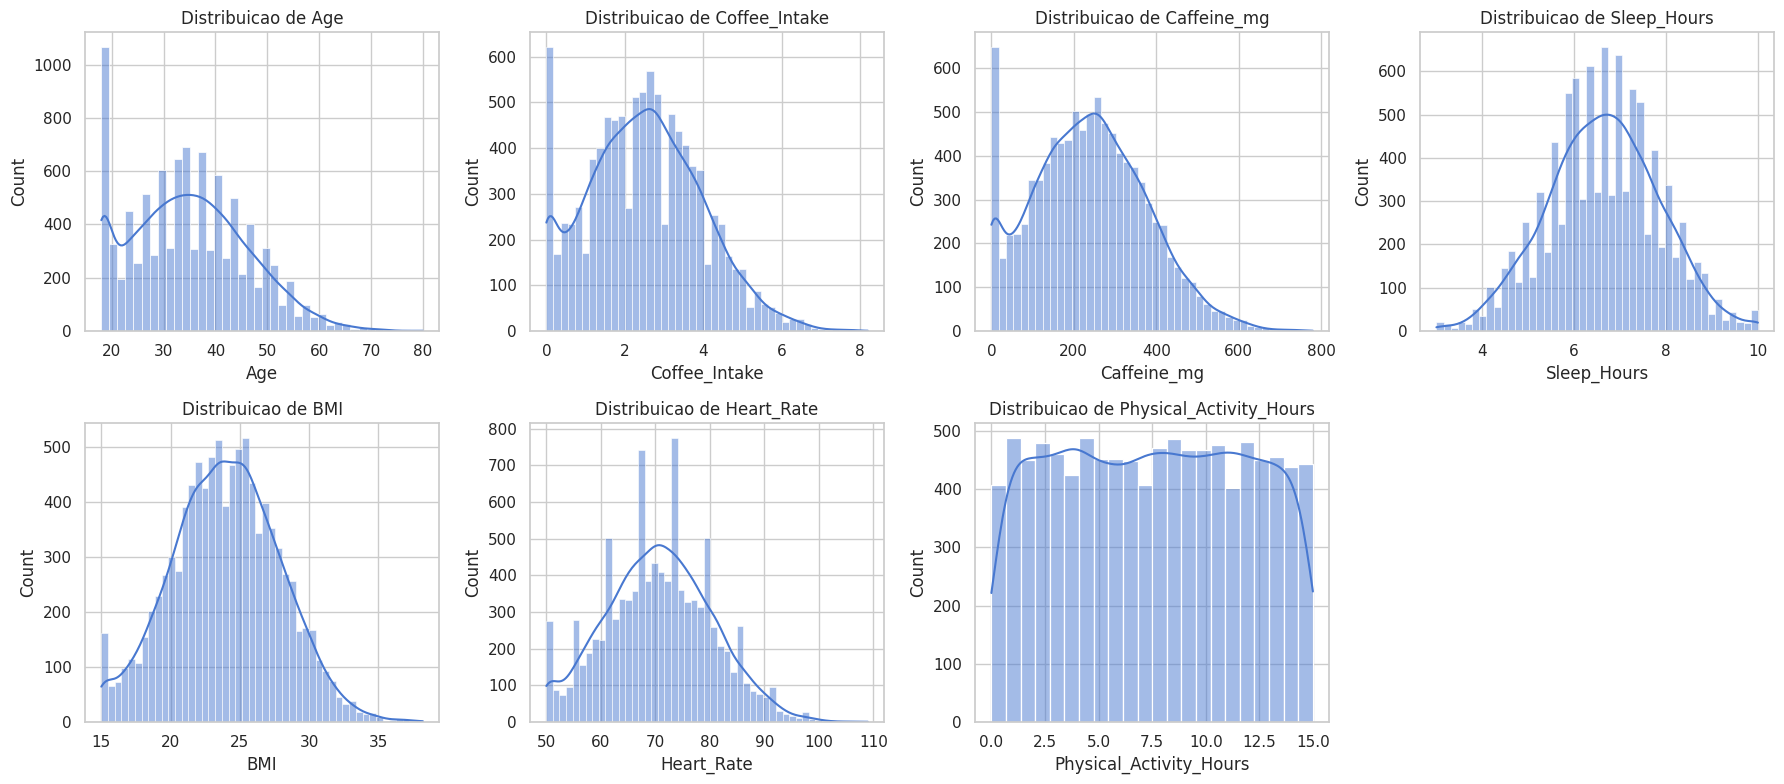

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), colunas_num):
  sns.histplot(df[col], kde=True, ax=ax)
  ax.set_title(f"Distribuicao de {col}")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()


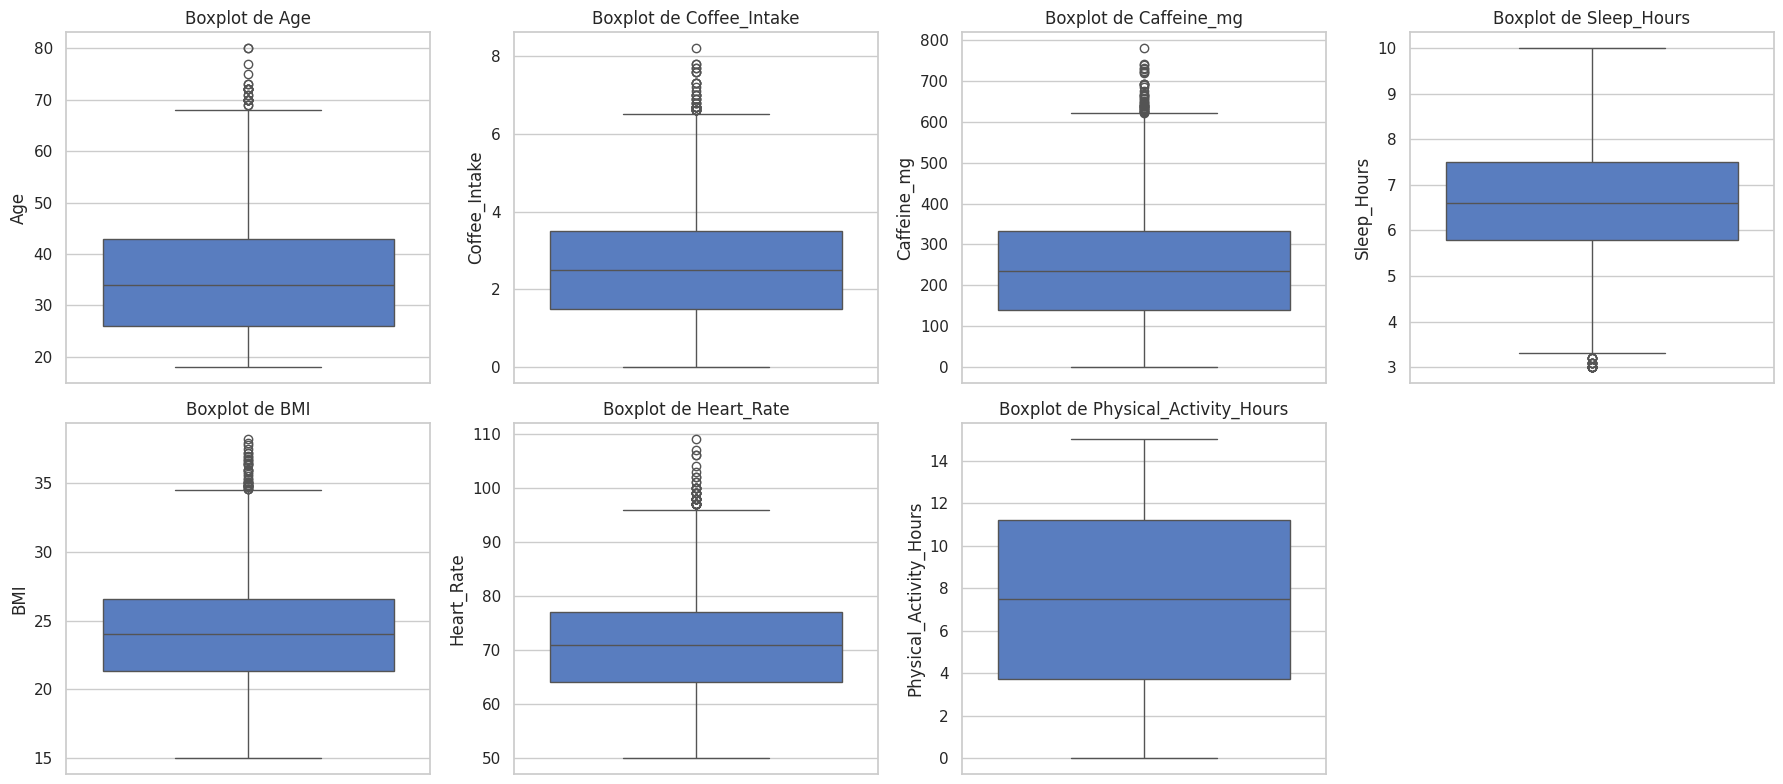

In [13]:
fig, axes = plt.subplots(2,4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), colunas_num):
  sns.boxplot(y=df[col], ax=ax)
  ax.set_title(f"Boxplot de {col}")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

##Passo 1.4 — Variáveis categóricas: barras e pizzas
Contamos quantas vezes cada categoria aparece. Usamos barras para todas e pizza para as que têm poucas categorias (Gender, Sleep_Quality, Stress_Level, Health_Issues). O Country tem 20 países, então usamos barras horizontais.

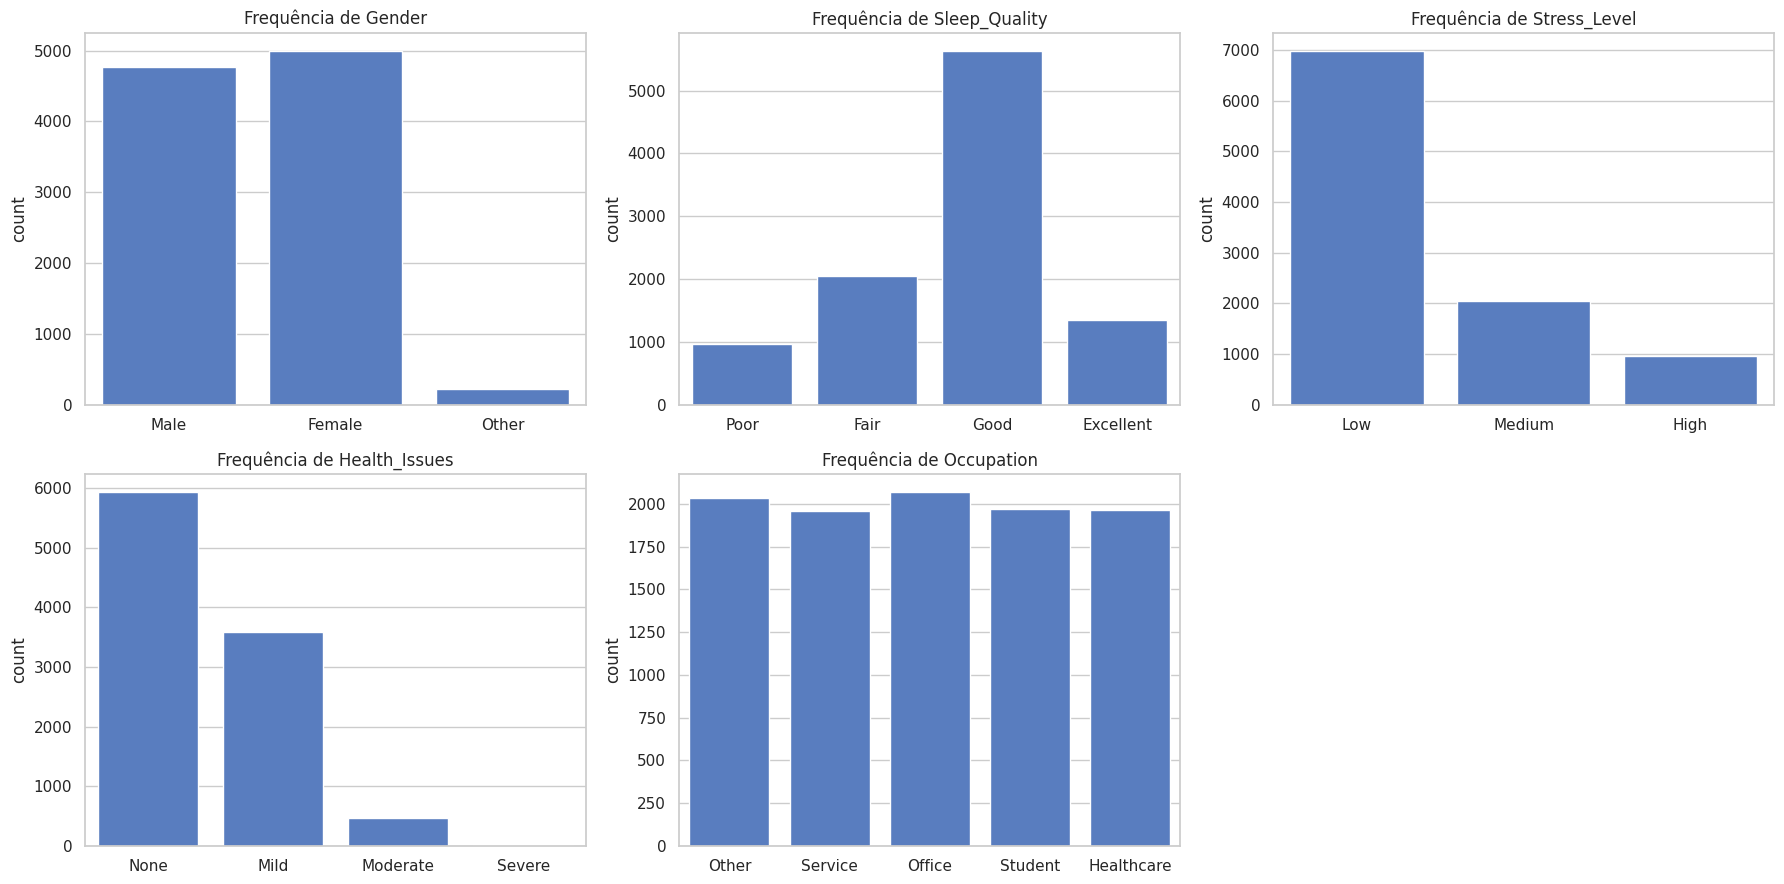

In [14]:
ordem = {
    "Sleep_Quality": ["Poor", "Fair", "Good", "Excellent"],
    "Stress_Level": ["Low", "Medium", "High"],
    "Health_Issues": ["None", "Mild", "Moderate", "Severe"],
}

cats_barras = ["Gender", "Sleep_Quality", "Stress_Level", "Health_Issues", "Occupation"]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), cats_barras):
  sns.countplot(data=df, x=col, order=ordem.get(col), ax=ax)
  ax.set_title(f"Frequência de {col}")
  ax.set_xlabel("")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

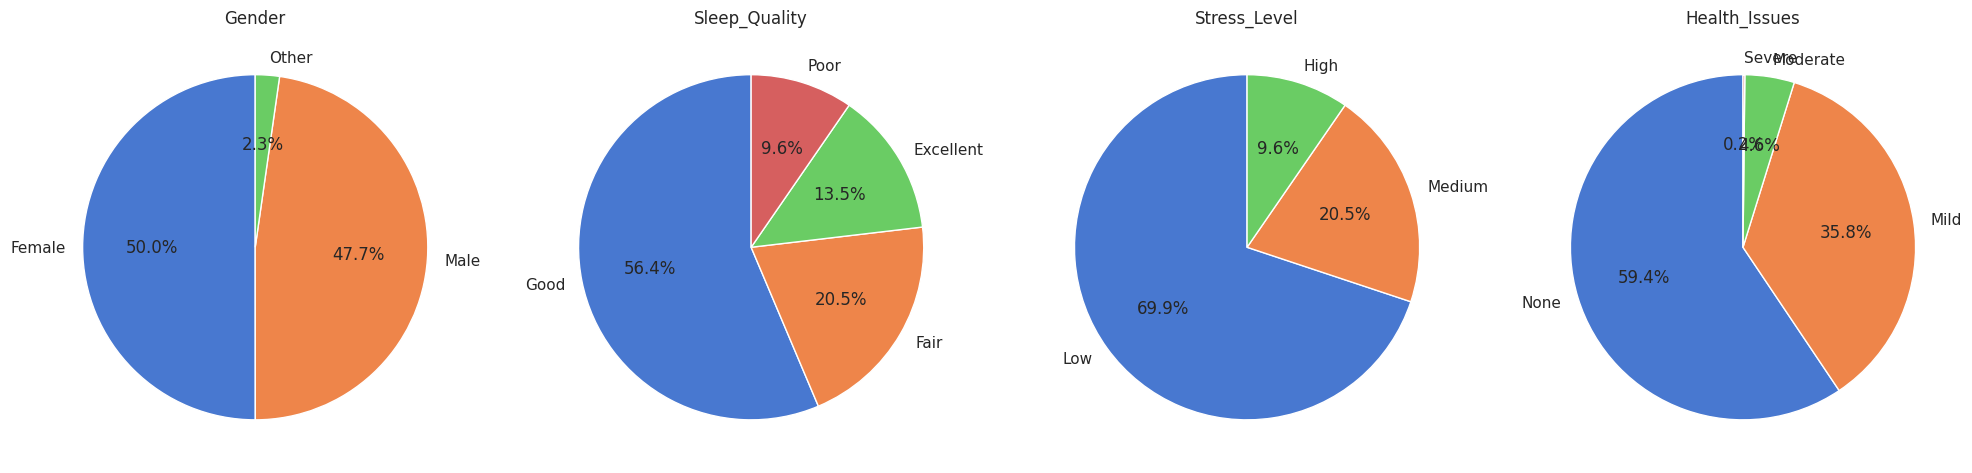

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, col in zip(axes, ["Gender", "Sleep_Quality", "Stress_Level", "Health_Issues"]):
    contagem = df[col].value_counts()
    ax.pie(contagem, labels=contagem.index, autopct="%1.1f%%", startangle=90)
    ax.set_title(col)
plt.tight_layout()
plt.show()

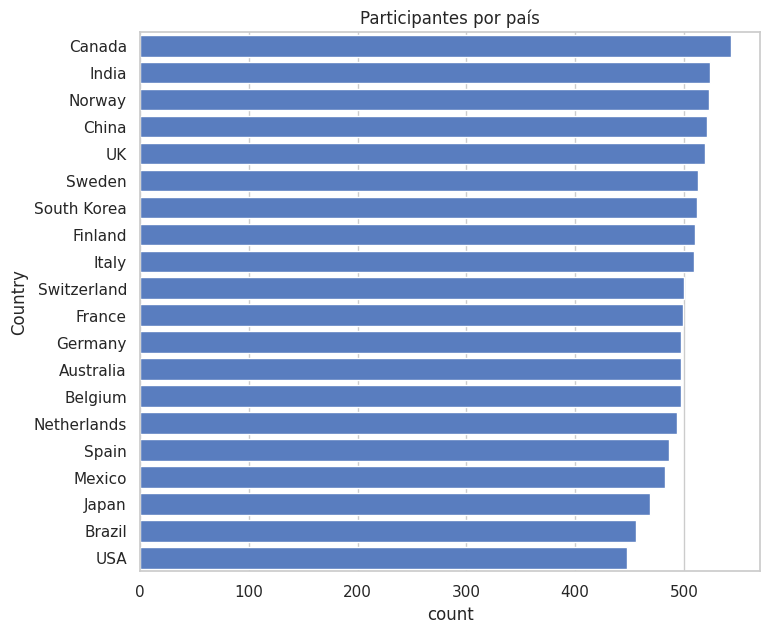

Smoking                0.200
Alcohol_Consumption    0.301
Name: proporção de 'Sim', dtype: float64


In [16]:
plt.figure(figsize=(8, 7))
sns.countplot(data=df, y="Country", order=df["Country"].value_counts().index)
plt.title("Participantes por país")
plt.show()

print(df[colunas_bool].mean().round(3).rename("proporção de 'Sim'"))

##Passo 1.5 — Correlações
A correlação de Pearson vai de -1 a +1:

- perto de +1: quando uma sobe, a outra sobe;
- perto de -1: quando uma sobe, a outra desce;
- perto de 0: sem relação linear.

Também vemos como o estresse se relaciona com a qualidade do sono (variáveis categóricas) usando uma tabela cruzada em %.

📌 Repare que Caffeine_mg ≈ Coffee_Intake × 95, então a correlação entre as duas deve ser ~1. Isso é redundância (vamos tratar na Parte 3).

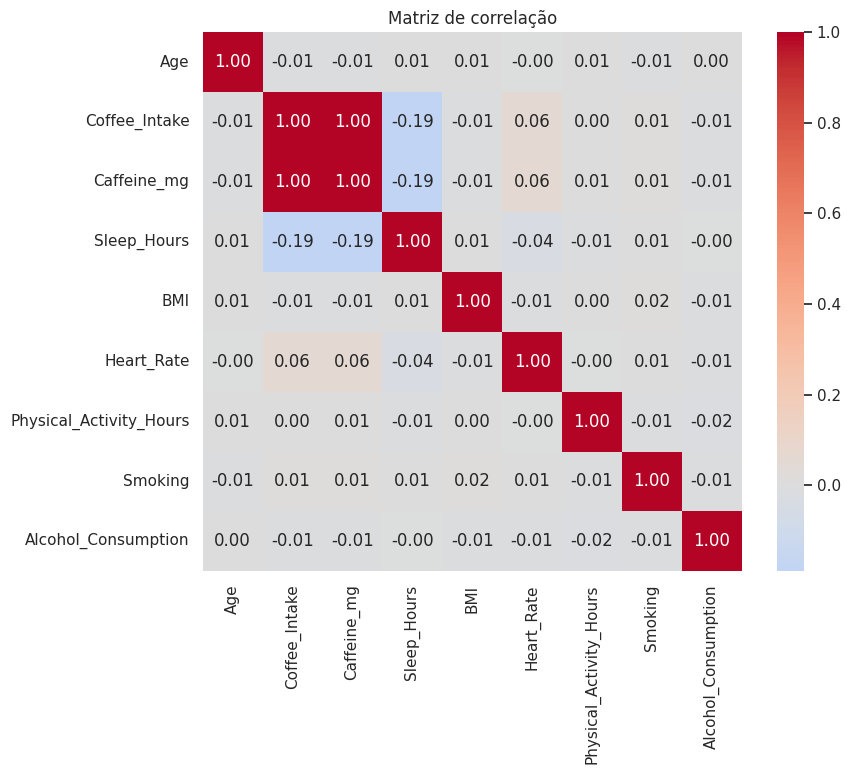

Correlação com Sleep_Hours:
Caffeine_mg               -0.190
Coffee_Intake             -0.190
Heart_Rate                -0.036
Physical_Activity_Hours   -0.011
Alcohol_Consumption       -0.003
Age                        0.005
Smoking                    0.008
BMI                        0.008
Name: Sleep_Hours, dtype: float64


In [17]:
plt.figure(figsize=(9, 7))
corr = df[colunas_num + colunas_bool].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Matriz de correlação")
plt.show()

print("Correlação com Sleep_Hours:")
print(corr["Sleep_Hours"].drop("Sleep_Hours").sort_values().round(3))

Sleep_Quality,Poor,Fair,Good,Excellent
Stress_Level,,,,
Low,0.0,0.0,80.7,19.3
Medium,0.0,100.0,0.0,0.0
High,100.0,0.0,0.0,0.0


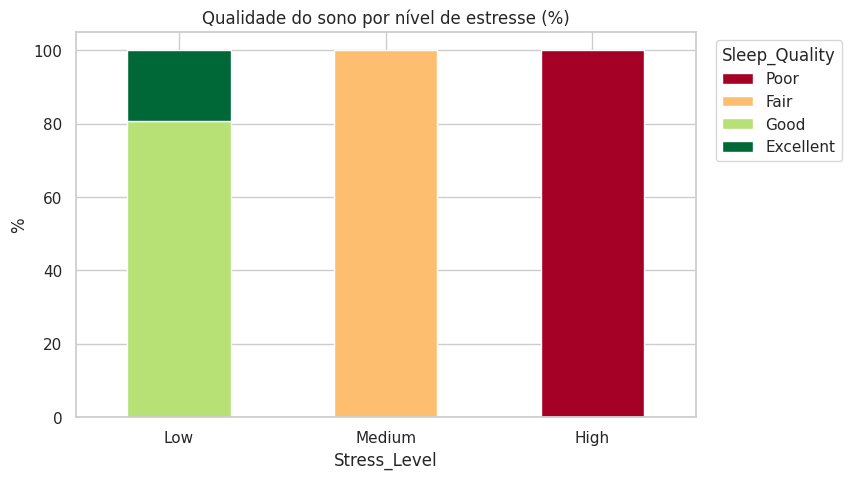

In [18]:
# Estresse x Qualidade do sono (em % por nível de estresse)
tab = pd.crosstab(df["Stress_Level"], df["Sleep_Quality"], normalize="index")[ordem["Sleep_Quality"]].loc[ordem["Stress_Level"]] * 100
display(tab.round(1))

tab.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="RdYlGn")
plt.title("Qualidade do sono por nível de estresse (%)")
plt.ylabel("%")
plt.xticks(rotation=0)
plt.legend(title="Sleep_Quality", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

 Seus achados da EDA
Edite esta célula com o que você observou (exemplos do que comentar):

* O dataset tem ___ linhas e ___ colunas; há / não há nulos e duplicados.
* A variável ___ é a mais assimétrica; há outliers em ___.
* A categoria mais frequente de Sleep_Quality é ___.
* Correlação entre Coffee_Intake e Sleep_Hours: ___ (negativa/positiva/fraca/forte).

#Parte 2 — Visualização e Insights
Agora comparamos grupos para responder perguntas de negócio: o café atrapalha o sono? O estresse piora tudo? Há diferença por gênero ou idade?

##Passo 2.1 — Café × horas de sono
Dispersão com linha de tendência: cada ponto é uma pessoa. Usamos uma amostra de 2.000 pontos só para o gráfico ficar legível.
Boxplot por faixa de consumo: agrupamos o café em faixas (0-1, 2-3, 4-5, 6+ xícaras) para comparar as horas de sono entre elas.

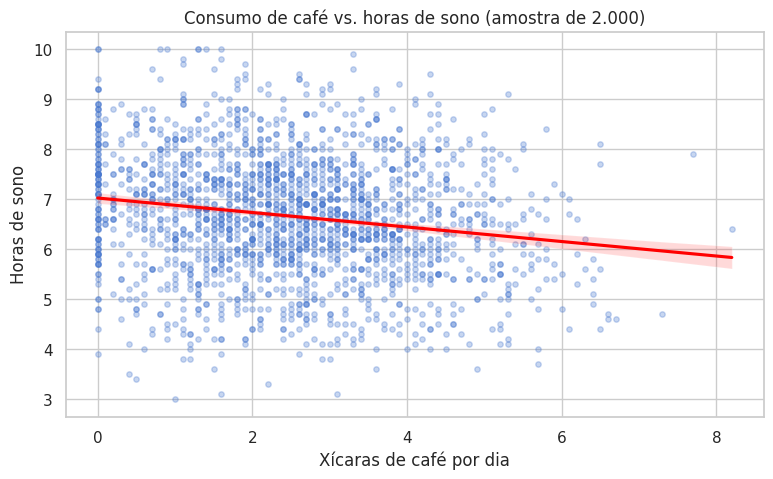

In [19]:
amostra = df.sample(2000, random_state=SEED)

plt.figure(figsize=(9, 5))
sns.regplot(data=amostra, x="Coffee_Intake", y="Sleep_Hours",
            scatter_kws={"alpha": 0.3, "s": 15}, line_kws={"color": "red"})
plt.title("Consumo de café vs. horas de sono (amostra de 2.000)")
plt.xlabel("Xícaras de café por dia")
plt.ylabel("Horas de sono")
plt.show()

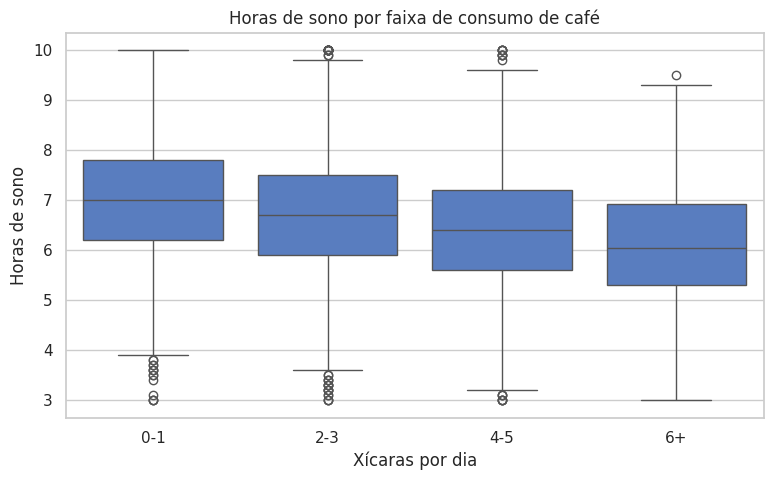

,Sleep_Hours
Coffee_Group,
0-1,6.96
2-3,6.71
4-5,6.41
6+,6.12


In [20]:
df["Coffee_Group"] = pd.cut(df["Coffee_Intake"], bins=[-0.01, 1, 3, 5, 100],
                            labels=["0-1", "2-3", "4-5", "6+"])

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Coffee_Group", y="Sleep_Hours")
plt.title("Horas de sono por faixa de consumo de café")
plt.xlabel("Xícaras por dia")
plt.ylabel("Horas de sono")
plt.show()

media_sono = df.groupby("Coffee_Group", observed=True)["Sleep_Hours"].mean().round(2)
display(media_sono)

Passo 2.2 — Estresse e qualidade do sono
Comparamos as horas de sono e o consumo de café entre os níveis de estresse. Se o estresse alto vier junto com mais café e menos sono, é um padrão importante para o negócio.

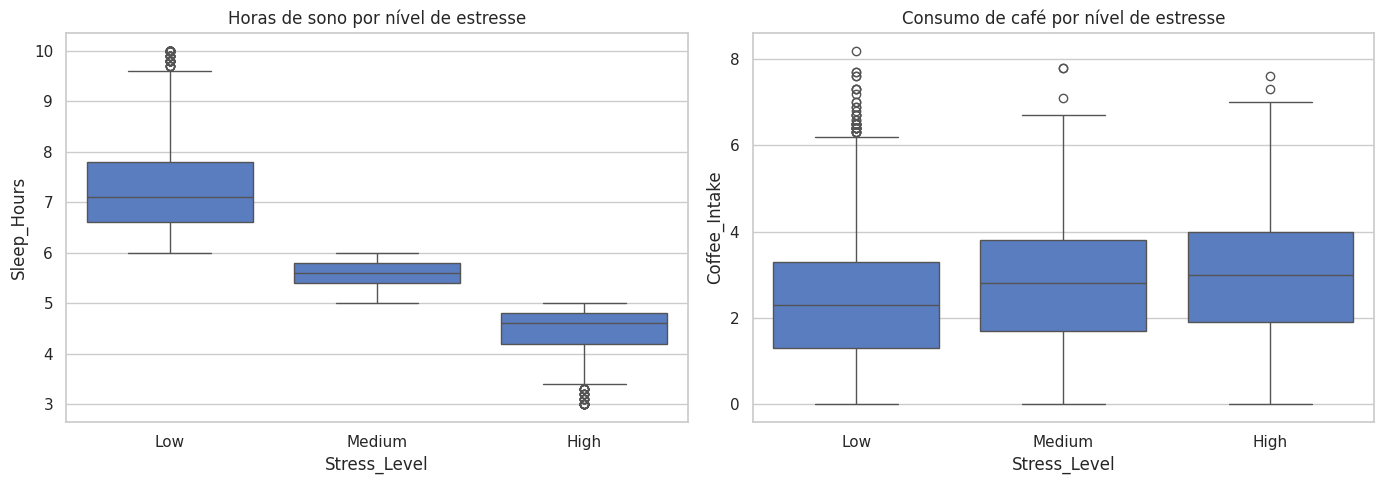

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="Stress_Level", y="Sleep_Hours", order=ordem["Stress_Level"], ax=axes[0])
axes[0].set_title("Horas de sono por nível de estresse")
sns.boxplot(data=df, x="Stress_Level", y="Coffee_Intake", order=ordem["Stress_Level"], ax=axes[1])
axes[1].set_title("Consumo de café por nível de estresse")
plt.tight_layout()
plt.show()

Passo 2.3 — Segmentação por grupos
Por gênero: o sono muda entre homens, mulheres e outros? Por idade: criamos faixas etárias e cruzamos idade × estresse × café em um mapa de calor (valor = média de xícaras por dia).

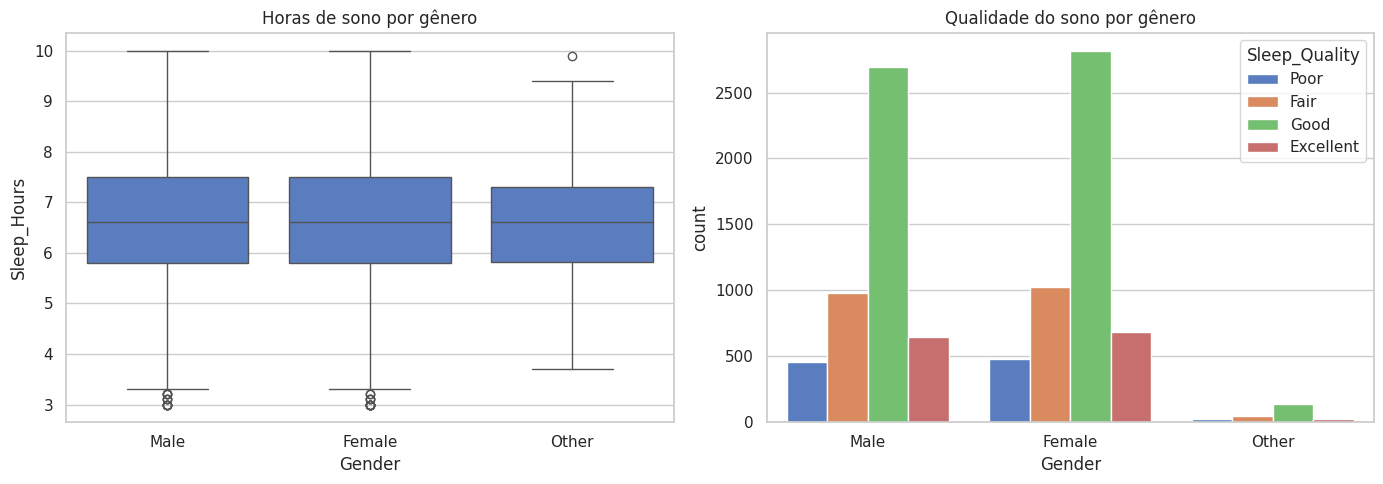

,mean,median,count
Gender,,,
Female,6.64,6.6,5001
Male,6.64,6.6,4773
Other,6.59,6.6,226


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="Gender", y="Sleep_Hours", ax=axes[0])
axes[0].set_title("Horas de sono por gênero")
sns.countplot(data=df, x="Gender", hue="Sleep_Quality", hue_order=ordem["Sleep_Quality"], ax=axes[1])
axes[1].set_title("Qualidade do sono por gênero")
plt.tight_layout()
plt.show()

display(df.groupby("Gender")["Sleep_Hours"].agg(["mean", "median", "count"]).round(2))

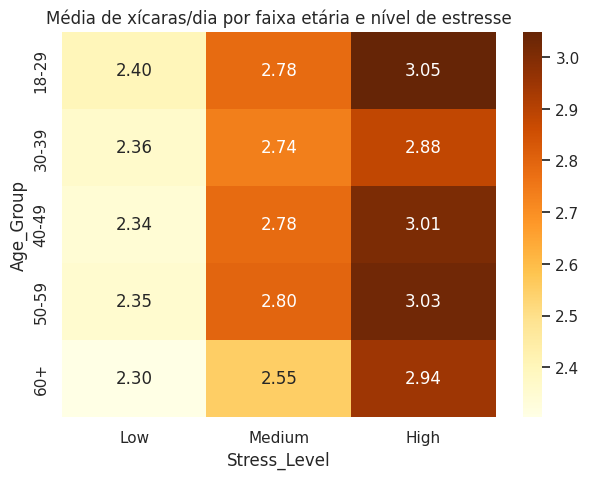

In [23]:
df["Age_Group"] = pd.cut(df["Age"], bins=[17, 29, 39, 49, 59, 80],
                         labels=["18-29", "30-39", "40-49", "50-59", "60+"])

pivot = df.pivot_table(index="Age_Group", columns="Stress_Level", values="Coffee_Intake",
                       aggfunc="mean", observed=True)[ordem["Stress_Level"]]

plt.figure(figsize=(7, 5))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlOrBr")
plt.title("Média de xícaras/dia por faixa etária e nível de estresse")
plt.show()

Passo 2.4 — Mapa de calor: sono × café × saúde
Mostramos quantas horas de sono (média) cada combinação faixa de café × nível de estresse tem, e como o consumo de café varia conforme os problemas de saúde.

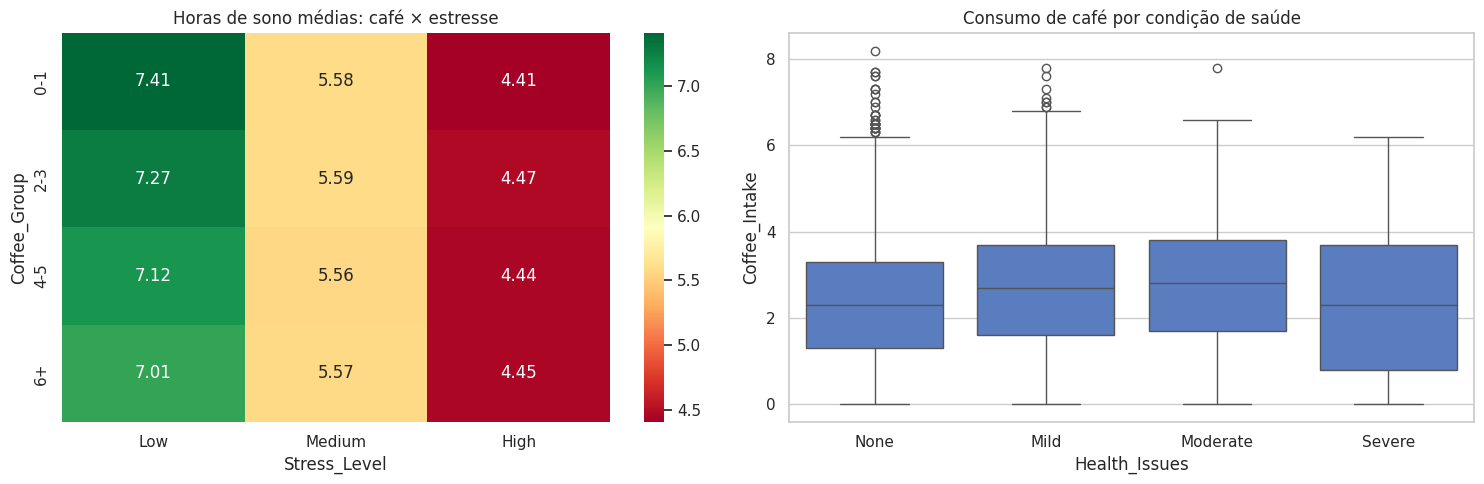

In [24]:
pivot2 = df.pivot_table(index="Coffee_Group", columns="Stress_Level", values="Sleep_Hours",
                        aggfunc="mean", observed=True)[ordem["Stress_Level"]]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(pivot2, annot=True, fmt=".2f", cmap="RdYlGn", ax=axes[0])
axes[0].set_title("Horas de sono médias: café × estresse")

sns.boxplot(data=df, x="Health_Issues", y="Coffee_Intake", order=ordem["Health_Issues"], ax=axes[1])
axes[1].set_title("Consumo de café por condição de saúde")
plt.tight_layout()
plt.show()

Passo 2.5 — 🔎 Principais Descobertas
A célula abaixo calcula os números automaticamente a partir dos dados e monta as frases de insight. Depois, use essas frases (e os gráficos acima) para escrever suas conclusões na célula de texto seguinte.

In [25]:
baixo = df.loc[df["Coffee_Intake"] <= 1, "Sleep_Hours"].mean()
alto = df.loc[df["Coffee_Intake"] >= 6, "Sleep_Hours"].mean()
corr_cs = df["Coffee_Intake"].corr(df["Sleep_Hours"])

print(f"1) Quem toma até 1 xícara dorme em média {baixo:.2f} h; quem toma 6+ xícaras dorme {alto:.2f} h "
      f"(diferença de {baixo - alto:.2f} h). Correlação café x sono: {corr_cs:.2f}.")

sono_estresse = df.groupby("Stress_Level")["Sleep_Hours"].mean().reindex(ordem["Stress_Level"])
print(f"\n2) Horas de sono médias por estresse -> " + ", ".join(f"{k}: {v:.2f} h" for k, v in sono_estresse.items()))

pct_ruim = (df.groupby("Stress_Level")["Sleep_Quality"].apply(lambda s: s.isin(["Poor", "Fair"]).mean()) * 100).reindex(ordem["Stress_Level"])
print(f"\n3) % de sono 'Poor' ou 'Fair' por estresse -> " + ", ".join(f"{k}: {v:.1f}%" for k, v in pct_ruim.items()))

sono_genero = df.groupby("Gender")["Sleep_Hours"].mean()
print(f"\n4) Horas de sono por gênero -> " + ", ".join(f"{k}: {v:.2f} h" for k, v in sono_genero.items()))

cafe_idade = df.groupby("Age_Group", observed=True)["Coffee_Intake"].mean()
print(f"\n5) Maior consumo de café: faixa {cafe_idade.idxmax()} ({cafe_idade.max():.2f} xícaras/dia); menor: faixa {cafe_idade.idxmin()} ({cafe_idade.min():.2f}).")

1) Quem toma até 1 xícara dorme em média 6.96 h; quem toma 6+ xícaras dorme 6.15 h (diferença de 0.81 h). Correlação café x sono: -0.19.

2) Horas de sono médias por estresse -> Low: 7.25 h, Medium: 5.58 h, High: 4.45 h

3) % de sono 'Poor' ou 'Fair' por estresse -> Low: 0.0%, Medium: 100.0%, High: 100.0%

4) Horas de sono por gênero -> Female: 6.64 h, Male: 6.64 h, Other: 6.59 h

5) Maior consumo de café: faixa 18-29 (2.54 xícaras/dia); menor: faixa 60+ (2.42).


Principais Descobertas (escreva com suas palavras)
Use os números impressos acima. Exemplo de formato:

- Café e sono: clientes com alto consumo de cafeína dormem em média ___ h a menos que quem bebe pouco café.
- Estresse: o nível de estresse ___ está associado a ___ (mais/menos horas de sono, pior qualidade).
- Gênero: ___ (há ou não diferença relevante).
- Idade: a faixa ___ consome mais café e tem ___.
- Atenção: correlação não é causalidade — este é um dataset sintético e os padrões devem ser vistos como indícios, não provas.

#Parte 3 — Modelo Preditivo
Meta: prever Sleep_Quality (Poor, Fair, Good, Excellent) a partir dos hábitos e características da pessoa. É um problema de classificação multiclasse.

###Passo 3.1 — Pré-processamento
Vamos preparar os dados para os algoritmos, que só entendem números:

- Remover colunas irrelevantes: ID (só identifica a linha, não tem poder preditivo) e Caffeine_mg (redundante: é praticamente Coffee_Intake × 95). Também removemos as colunas auxiliares que criamos para os gráficos (Coffee_Group, Age_Group).

- Criar features derivadas (informação nova a partir das existentes):
     - Coffee_per_Sleep_Hour = xícaras ÷ horas de sono (café "relativo" ao sono);
     - Heavy_Coffee = 1 se toma 4+ xícaras por dia.
- Codificar categóricas:
     - Ordinais (têm ordem natural): Stress_Level e Health_Issues → 0, 1, 2…
     - Nominais (sem ordem): Gender, Country, Occupation → one-hot encoding (uma coluna 0/1 por categoria).
     - Alvo Sleep_Quality → 0 (Poor) a 3 (Excellent).


In [26]:
df_model = df.drop(columns=["ID", "Caffeine_mg", "Coffee_Group", "Age_Group"]).copy()

# --- Features derivadas ---
df_model["Coffee_per_Sleep_Hour"] = df_model["Coffee_Intake"] / df_model["Sleep_Hours"]
df_model["Heavy_Coffee"] = (df_model["Coffee_Intake"] >= 4).astype(int)

# --- Codificação ordinal ---
df_model["Stress_Level"] = df_model["Stress_Level"].map({"Low": 0, "Medium": 1, "High": 2})
df_model["Health_Issues"] = df_model["Health_Issues"].map({"None": 0, "Mild": 1, "Moderate": 2, "Severe": 3})

# --- Alvo ---
mapa_alvo = {"Poor": 0, "Fair": 1, "Good": 2, "Excellent": 3}
nomes_classes = list(mapa_alvo.keys())
df_model["Sleep_Quality"] = df_model["Sleep_Quality"].map(mapa_alvo)

# --- One-hot nas nominais ---
df_model = pd.get_dummies(df_model, columns=["Gender", "Country", "Occupation"], drop_first=True, dtype=int)

print("Nulos após o tratamento:", df_model.isnull().sum().sum())
print("Formato final:", df_model.shape)
df_model.head()

Nulos após o tratamento: 0
Formato final: (10000, 38)


,Age,Coffee_Intake,Sleep_Hours,Sleep_Quality,BMI,Heart_Rate,Stress_Level,Physical_Activity_Hours,Health_Issues,Smoking,...,Country_South Korea,Country_Spain,Country_Sweden,Country_Switzerland,Country_UK,Country_USA,Occupation_Office,Occupation_Other,Occupation_Service,Occupation_Student
0,40,3.5,7.5,2,24.9,78,0,14.5,0,0,...,0,0,0,0,0,0,0,1,0,0
1,33,1.0,6.2,2,20.0,67,0,11.0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,42,5.3,5.9,1,22.7,59,1,11.2,1,0,...,0,0,0,0,0,0,1,0,0,0
3,53,2.6,7.3,2,24.7,71,0,6.6,1,0,...,0,0,0,0,0,0,0,1,0,0
4,32,3.1,5.3,1,24.1,76,1,8.5,1,0,...,0,1,0,0,0,0,0,0,0,1


##Passo 3.2 — Separar treino e teste
Separamos X (variáveis de entrada) e y (o que queremos prever). Depois dividimos em:

- 80% treino → o modelo aprende;
- 20% teste → avaliamos em dados que o modelo nunca viu.
stratify=y mantém a mesma proporção de cada classe nos dois conjuntos.

In [27]:
X = df_model.drop(columns=["Sleep_Quality"])
y = df_model["Sleep_Quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print("\nProporção das classes no treino:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

Treino: (8000, 37) | Teste: (2000, 37)

Proporção das classes no treino:
Sleep_Quality
0    0.096
1    0.205
2    0.564
3    0.135
Name: proportion, dtype: float64


###Passo 3.3 — Treinar dois modelos


Modelo

- Regressão Logística	Modelo linear simples e rápido, bom ponto de partida. Precisa de variáveis na mesma escala, por isso usamos StandardScaler dentro de um pipeline.
-   Random Forest	Várias árvores de decisão votando juntas. Captura relações não lineares e não precisa de escala.


Com o .fit() o modelo aprende a partir do treino; com o .predict() ele gera previsões.

In [28]:
modelos = {
    "Regressão Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
}

resultados = {}
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)
    resultados[nome] = {
        "Acurácia treino": accuracy_score(y_train, pred_train),
        "Acurácia teste": accuracy_score(y_test, pred_test),
        "pred_test": pred_test,
    }

comparacao = pd.DataFrame(resultados).T[["Acurácia treino", "Acurácia teste"]].astype(float)
comparacao["Diferença (treino - teste)"] = comparacao["Acurácia treino"] - comparacao["Acurácia teste"]
display(comparacao.round(4))

,Acurácia treino,Acurácia teste,Diferença (treino - teste)
Regressão Logística,0.9938,0.992,0.0018
Random Forest,1.0000,0.992,0.0080


##Passo 3.4 — Avaliar os modelos
 - Acurácia: % de acertos.
 - Relatório de classificação: precision (dos que previ como X, quantos eram X), recall (dos que eram X, quantos achei) e f1 (equilíbrio entre os dois), por classe.
 - Matriz de confusão: linhas = classe real, colunas = classe prevista. A diagonal são os acertos; fora dela, os erros.

Regressão Logística
              precision    recall  f1-score   support

        Poor       1.00      1.00      1.00       192
        Fair       1.00      1.00      1.00       410
        Good       0.99      0.99      0.99      1128
   Excellent       0.97      0.97      0.97       270

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000

Random Forest
              precision    recall  f1-score   support

        Poor       1.00      1.00      1.00       192
        Fair       1.00      1.00      1.00       410
        Good       0.99      1.00      0.99      1128
   Excellent       0.99      0.95      0.97       270

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000



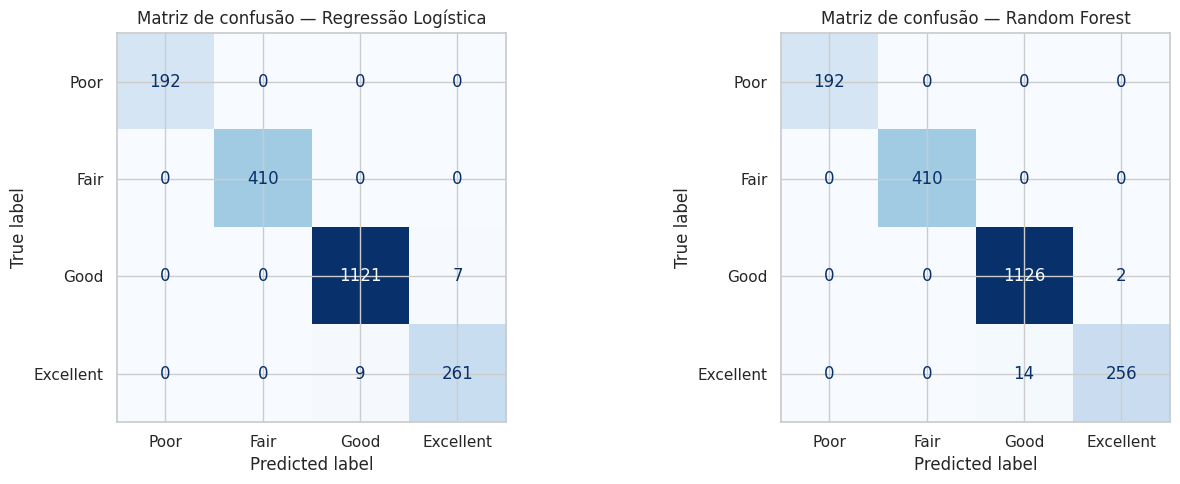

In [29]:
for nome in modelos:
    print("=" * 60)
    print(nome)
    print("=" * 60)
    print(classification_report(y_test, resultados[nome]["pred_test"], target_names=nomes_classes, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, nome in zip(axes, modelos):
    cm = confusion_matrix(y_test, resultados[nome]["pred_test"])
    ConfusionMatrixDisplay(cm, display_labels=nomes_classes).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Matriz de confusão — {nome}")
plt.tight_layout()
plt.show()

##Passo 3.5 — Overfitting ou underfitting?
- Overfitting: vai muito bem no treino e bem pior no teste (o modelo "decorou").
- Underfitting: vai mal nos dois (o modelo é simples demais ou faltam informações).
A célula abaixo compara os números e diz qual modelo foi melhor.

In [30]:
melhor_nome = comparacao["Acurácia teste"].idxmax()
print(f"🏆 Melhor modelo no teste: {melhor_nome} ({comparacao.loc[melhor_nome, 'Acurácia teste']:.2%})\n")

for nome, linha in comparacao.iterrows():
    gap = linha["Diferença (treino - teste)"]
    if gap > 0.10:
        diag = "possível OVERFITTING (treino muito acima do teste)"
    elif linha["Acurácia teste"] < 0.60:
        diag = "possível UNDERFITTING (desempenho baixo nos dois)"
    else:
        diag = "bom equilíbrio entre treino e teste"
    print(f"- {nome}: treino {linha['Acurácia treino']:.2%} | teste {linha['Acurácia teste']:.2%} | diferença {gap:.2%} -> {diag}")

🏆 Melhor modelo no teste: Regressão Logística (99.20%)

- Regressão Logística: treino 99.38% | teste 99.20% | diferença 0.18% -> bom equilíbrio entre treino e teste
- Random Forest: treino 100.00% | teste 99.20% | diferença 0.80% -> bom equilíbrio entre treino e teste


## Passo 3.5b —  Teste extra: e se tirarmos Sleep_Hours?
Sleep_Hours (horas dormidas) é uma medida do próprio sono, então ela pode "entregar" a resposta sobre a qualidade. Se a acurácia acima ficou muito alta (perto de 100%), isso é um sinal de alerta (vazamento de informação).

Esta célula treina o Random Forest sem Sleep_Hours e sem a feature derivada que depende dela, para ver o quanto o modelo acerta usando apenas hábitos e características do cliente. Comente essa diferença no seu relatório.

In [32]:
X_sem = X.drop(columns=["Sleep_Hours", "Coffee_per_Sleep_Hour"])
Xtr, Xte, ytr, yte = train_test_split(X_sem, y, test_size=0.2, random_state=SEED, stratify=y)

rf_sem = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1).fit(Xtr, ytr)
print(f"Random Forest SEM Sleep_Hours -> treino: {rf_sem.score(Xtr, ytr):.2%} | teste: {rf_sem.score(Xte, yte):.2%}")
print(f"Random Forest COM Sleep_Hours -> teste: {comparacao.loc['Random Forest', 'Acurácia teste']:.2%}")

Random Forest SEM Sleep_Hours -> treino: 100.00% | teste: 86.50%
Random Forest COM Sleep_Hours -> teste: 99.20%


##Passo 3.6 — O que mais pesa na previsão? (importância das variáveis)

O Random Forest informa quanto cada variável contribuiu para as decisões. Isso ajuda a transformar o modelo em recomendações de negócio.

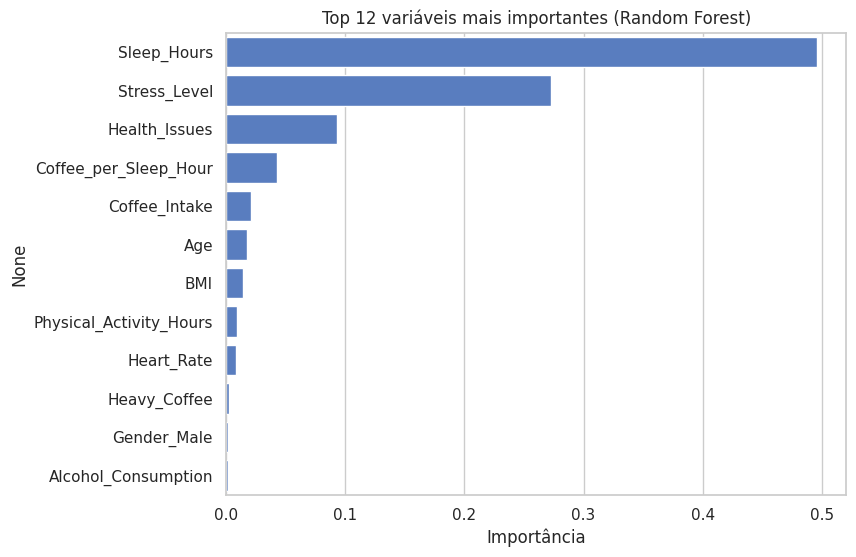

In [33]:
rf = modelos["Random Forest"]
importancias = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(12)

plt.figure(figsize=(8, 6))
sns.barplot(x=importancias.values, y=importancias.index)
plt.title("Top 12 variáveis mais importantes (Random Forest)")
plt.xlabel("Importância")
plt.show()

##Passo 3.7 — Salvar os resultados
Salvamos:

 - o dataset processado em CSV (dataset_processado.csv);
 - o melhor modelo com joblib (melhor_modelo.joblib), junto com os nomes das colunas e das classes — assim ele pode ser reutilizado depois sem retreinar.
No Colab os arquivos ficam na pasta temporária da sessão (somem quando ela é encerrada), então a última linha faz o download para o seu computador. Depois, suba-os no GitHub.

In [34]:
df_model.to_csv("dataset_processado.csv", index=False)

joblib.dump({
    "modelo": modelos[melhor_nome],
    "nome_modelo": melhor_nome,
    "colunas": list(X.columns),
    "classes": nomes_classes,
}, "melhor_modelo.joblib")

print("Arquivos salvos: dataset_processado.csv e melhor_modelo.joblib")

# Download automático (só funciona no Colab)
try:
    from google.colab import files
    files.download("dataset_processado.csv")
    files.download("melhor_modelo.joblib")
except ImportError:
    pass

Arquivos salvos: dataset_processado.csv e melhor_modelo.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 💼 Recomendações para o Negócio
Complete com os resultados que você obteve (os números mudam conforme os dados reais):

 - Modelo: o ___ atingiu ___% de acurácia no teste e pode ser usado para sinalizar clientes com risco de sono ruim (classes Poor/Fair).
 - Hábitos de café: como as variáveis ___ e ___ foram as mais importantes, orientar os clientes a reduzir/concentrar o café mais cedo pode ajudar a melhorar o sono.
 - Estresse: clientes com estresse High tendem a ___; oferecer conteúdo de gestão de estresse e rotina de sono.
 - Segmentação: campanhas diferentes por faixa etária e gênero, conforme os padrões da Parte 2.
 - Limitações e próximos passos: dados sintéticos; testar outros modelos (Gradient Boosting), ajustar hiperparâmetros com validação cruzada e coletar mais variáveis (horário do café, tipo de bebida).
